# Mission - Prédisez la consommation d'énergie des bâtiments

---

## Importation des bibliothèques

- **pandas** : manipulation et exploration de données.
- **matplotlib** / **seaborn** : création de graphiques.
- **numpy** : manipulation des tableaux numériques.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np
import ipywidgets as widgets
from ipywidgets import interact

## Chargement des données

On charge le fichier CSV contenant les données de consommation énergétique des bâtiments.

In [2]:
# On regarde comment le jeu de données est défini
df = pd.read_csv("./assets/2016_Building_Energy_Benchmarking.csv")
df.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


## Inspection du dataset

On examine la structure générale des données avec `.info()` afin d'identifier :
- Le nombre de valeurs non nulles par colonne.
- Les types de données (`object`, `float64`, `int64`, etc.).

In [3]:
# regarde les infos pour prendre connaissance du nombre de valeurs manquantes ainsi que le type 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

Ici, nous affichons le nombre total de lignes présentes dans le DataFrame.
Cela nous donne une idée de la taille du jeu de données et permet de suivre l'évolution du nombre de lignes après les étapes de filtrage et nettoyage.

In [4]:
print("Nombres de ligne :", len(df))

Nombres de ligne : 3376


## Statistiques :

L'utilisation de `.describe()` permet d'obtenir un résumé statistique des colonnes numériques :
- Moyenne
- Médiane
- Minimum et maximum 
- ect...

In [5]:
# Déscription de chaques colonnes :
df.describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,...,SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity
count,3376.000000,3376.0,3360.000000,3376.000000,3376.000000,3376.000000,3376.000000,3368.000000,3376.000000,3.376000e+03,...,3.371000e+03,3.370000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,0.0,3367.000000,3367.000000
mean,21208.991114,2016.0,98116.949107,4.439277,47.624033,-122.334795,1968.573164,1.106888,4.709123,9.483354e+04,...,5.403667e+06,5.276726e+06,2.745959e+05,1.086639e+06,3.707612e+06,1.368505e+04,1.368505e+06,NaN,119.723971,1.175916
std,12223.757015,0.0,18.615205,2.120625,0.047758,0.027203,33.088156,2.108402,5.494465,2.188376e+05,...,2.161063e+07,1.593879e+07,3.912173e+06,4.352478e+06,1.485066e+07,6.709781e+04,6.709781e+06,NaN,538.832227,1.821452
min,1.000000,2016.0,98006.000000,1.000000,47.499170,-122.414250,1900.000000,0.000000,0.000000,1.128500e+04,...,0.000000e+00,0.000000e+00,0.000000e+00,-3.382680e+04,-1.154170e+05,0.000000e+00,0.000000e+00,NaN,-0.800000,-0.020000
25%,19990.750000,2016.0,98105.000000,3.000000,47.599860,-122.350662,1948.000000,1.000000,2.000000,2.848700e+04,...,9.251286e+05,9.701822e+05,0.000000e+00,1.874229e+05,6.394870e+05,0.000000e+00,0.000000e+00,NaN,9.495000,0.210000
50%,23112.000000,2016.0,98115.000000,4.000000,47.618675,-122.332495,1975.000000,1.000000,4.000000,4.417500e+04,...,1.803753e+06,1.904452e+06,0.000000e+00,3.451299e+05,1.177583e+06,3.237538e+03,3.237540e+05,NaN,33.920000,0.610000
75%,25994.250000,2016.0,98122.000000,7.000000,47.657115,-122.319407,1997.000000,1.000000,5.000000,9.099200e+04,...,4.222455e+06,4.381429e+06,0.000000e+00,8.293178e+05,2.829632e+06,1.189033e+04,1.189034e+06,NaN,93.940000,1.370000
max,50226.000000,2016.0,98272.000000,7.000000,47.733870,-122.220966,2015.000000,111.000000,99.000000,9.320156e+06,...,8.739237e+08,4.716139e+08,1.349435e+08,1.925775e+08,6.570744e+08,2.979090e+06,2.979090e+08,NaN,16870.980000,34.090000


## Analyse des types de bâtiments
On compte le nombre d'occurrences pour chaque type de bâtiment (`BuildingType`).
Cette étape permet de comprendre la répartition des bâtiments selon leur usage global (résidentiel, non résidentiel, etc.).

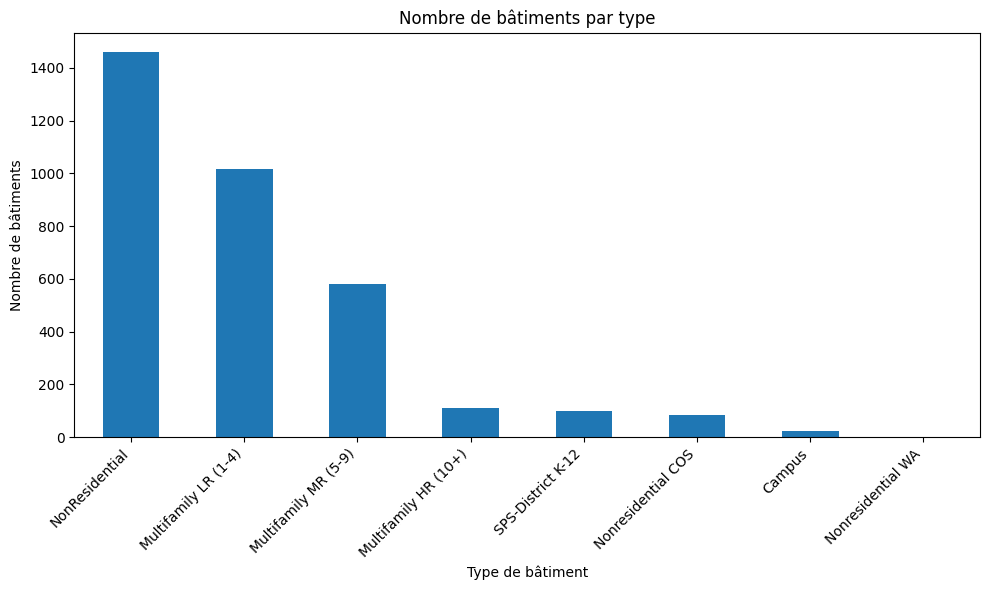

In [6]:
# Identification des types de batiments
building_counts = df['BuildingType'].value_counts()

plt.figure(figsize=(10, 6))
building_counts.plot(kind='bar')

plt.title("Nombre de bâtiments par type")
plt.xlabel("Type de bâtiment")
plt.ylabel("Nombre de bâtiments")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

Comme l'objectif est de prédire la consommation des bâtiments non résidentiels, on filtre le DataFrame pour ne conserver que ces derniers.

In [7]:
# Je vais cibler les batiments non residentiel donc supprimer plusieurs lignes
df.drop(df[df['BuildingType']  == 'Multifamily LR (1-4)'].index, inplace=True)
df.drop(df[df['BuildingType']  == 'Multifamily MR (5-9)'].index, inplace=True)
df.drop(df[df['BuildingType']  == 'Multifamily HR (10+)'].index, inplace=True)

## Visualisation après filtrage

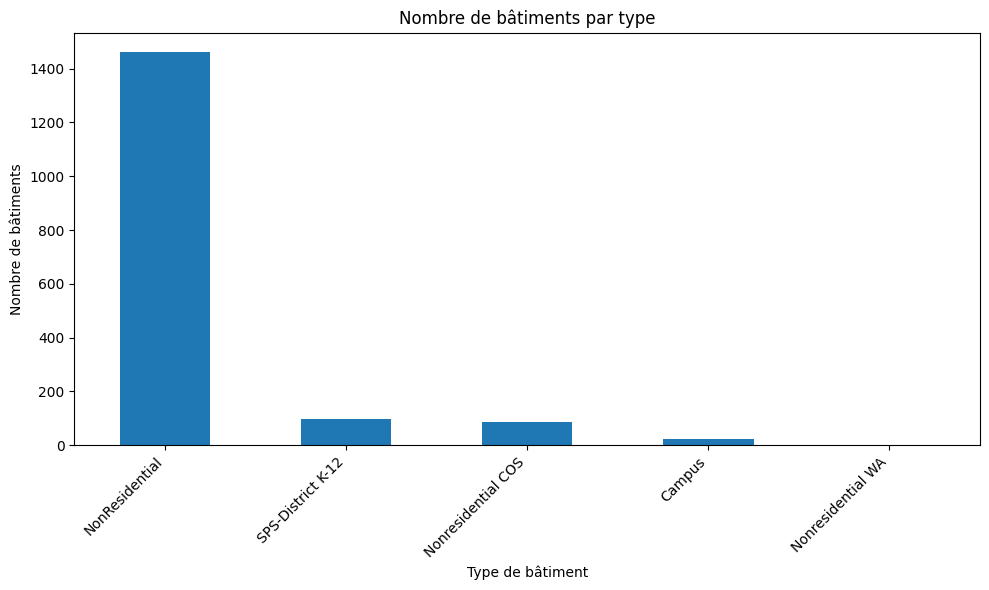

In [8]:
# Graphique après suppression des batiments 
building_counts = df['BuildingType'].value_counts()

plt.figure(figsize=(10, 6))
building_counts.plot(kind='bar')


plt.title("Nombre de bâtiments par type")
plt.xlabel("Type de bâtiment")
plt.ylabel("Nombre de bâtiments")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

## Identification des colonnes à valeur unique
Ici, on recherche les colonnes contenant une seule valeur unique.
Ces colonnes sont inutiles pour la modélisation car elles n'apportent aucune variabilité et peuvent être supprimées pour réduire la complexité du dataset.

In [9]:
unique_value_columns = [col for col in df.columns if df[col].nunique() <= 1]

print("Colonnes avec valeur unique :")
for col in unique_value_columns:
    print(col)

Colonnes avec valeur unique :
DataYear
City
State
Comments


In [10]:
# Affichage des valeurs uniques pour analyse
print(df['ComplianceStatus'].value_counts(dropna=False))
print(df['DefaultData'].value_counts(dropna=False))

# Filtrage : suppression des lignes où les données sont marquées comme non conformes ou par défaut
avant = df.shape[0]
df = df[df['ComplianceStatus'].isin(['Compliant'])]  # exemple à adapter
df = df[df['DefaultData'] != True]  
apres = df.shape[0]

print(f"Lignes supprimées : {avant - apres}")


ComplianceStatus
Compliant                       1548
Error - Correct Default Data      88
Non-Compliant                     18
Missing Data                      14
Name: count, dtype: int64
DefaultData
False    1580
True       88
Name: count, dtype: int64
Lignes supprimées : 120


Suppression des colonnes nettoyées

In [11]:
df.drop(columns=['ComplianceStatus', 'DefaultData', "Outlier", "DataYear", "City", "State", "Comments", "Address", "Latitude", "Longitude"], inplace=True, errors='ignore')

Conformiter des types :

type int :

In [12]:
int_cols = []
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        # Convertir en float et vérifier si toutes les valeurs non NaN sont entières
        if df[col].dropna().apply(lambda x: float(x).is_integer()).all():
            int_cols.append(col)

for col in int_cols:
    df[col] = df[col].astype("Int64")

type category

In [13]:
cat_candidates = []
for col in df.columns:
    if pd.api.types.is_object_dtype(df[col]):
        nunique = df[col].nunique(dropna=True)
        # seuil : ici <= 50 modalités uniques
        if nunique <= 50:
            cat_candidates.append(col)


for col in cat_candidates:
    df[col] = df[col].astype("category")

nettoyage de la variable `Neighborhood`

In [14]:
print("Avant :", df["Neighborhood"].nunique(dropna=True))
display(df["Neighborhood"].value_counts(dropna=False))

s = df["Neighborhood"].astype("string")
s = s.str.strip()
s = s.str.replace(r"[_\-]+", " ", regex=True)
s = s.str.replace(r"\s+", " ", regex=True)
df["Neighborhood"] = s.str.lower().str.title()

print("Après :", df["Neighborhood"].nunique(dropna=True))
display(df["Neighborhood"].value_counts(dropna=False))

Avant : 19


Neighborhood
DOWNTOWN                  351
GREATER DUWAMISH          328
MAGNOLIA / QUEEN ANNE     144
LAKE UNION                143
NORTHEAST                 117
EAST                      116
NORTHWEST                  74
BALLARD                    58
NORTH                      51
CENTRAL                    42
DELRIDGE                   36
SOUTHEAST                  31
SOUTHWEST                  31
North                       8
Ballard                     5
Central                     4
Delridge                    4
Northwest                   4
DELRIDGE NEIGHBORHOODS      1
Name: count, dtype: int64

Après : 14


Neighborhood
Downtown                  351
Greater Duwamish          328
Magnolia / Queen Anne     144
Lake Union                143
Northeast                 117
East                      116
Northwest                  78
Ballard                    63
North                      59
Central                    46
Delridge                   40
Southwest                  31
Southeast                  31
Delridge Neighborhoods      1
Name: count, dtype: Int64

## Identification des valeurs manquantes
On calcule le pourcentage de valeurs manquantes par colonne.
Cela permet :
- D'identifier les colonnes trop incomplètes pour être utiles.
- De décider si on va les supprimer ou remplir les valeurs manquantes.

In [15]:
missing_ratio = df.isnull().mean().sort_values(ascending=False)
colonnes_a_forte_na = missing_ratio[missing_ratio > 0.5]
print("\nColonnes avec plus de 50% de valeurs manquantes :")
print(colonnes_a_forte_na)
df.drop(columns=colonnes_a_forte_na.index, inplace=True)


Colonnes avec plus de 50% de valeurs manquantes :
YearsENERGYSTARCertified          0.937339
ThirdLargestPropertyUseType       0.775194
ThirdLargestPropertyUseTypeGFA    0.775194
dtype: float64


Suppression des doublons via OSEBuildingID

In [16]:
if "OSEBuildingID" in df.columns:
    df.drop_duplicates(subset=["OSEBuildingID"], inplace=True)


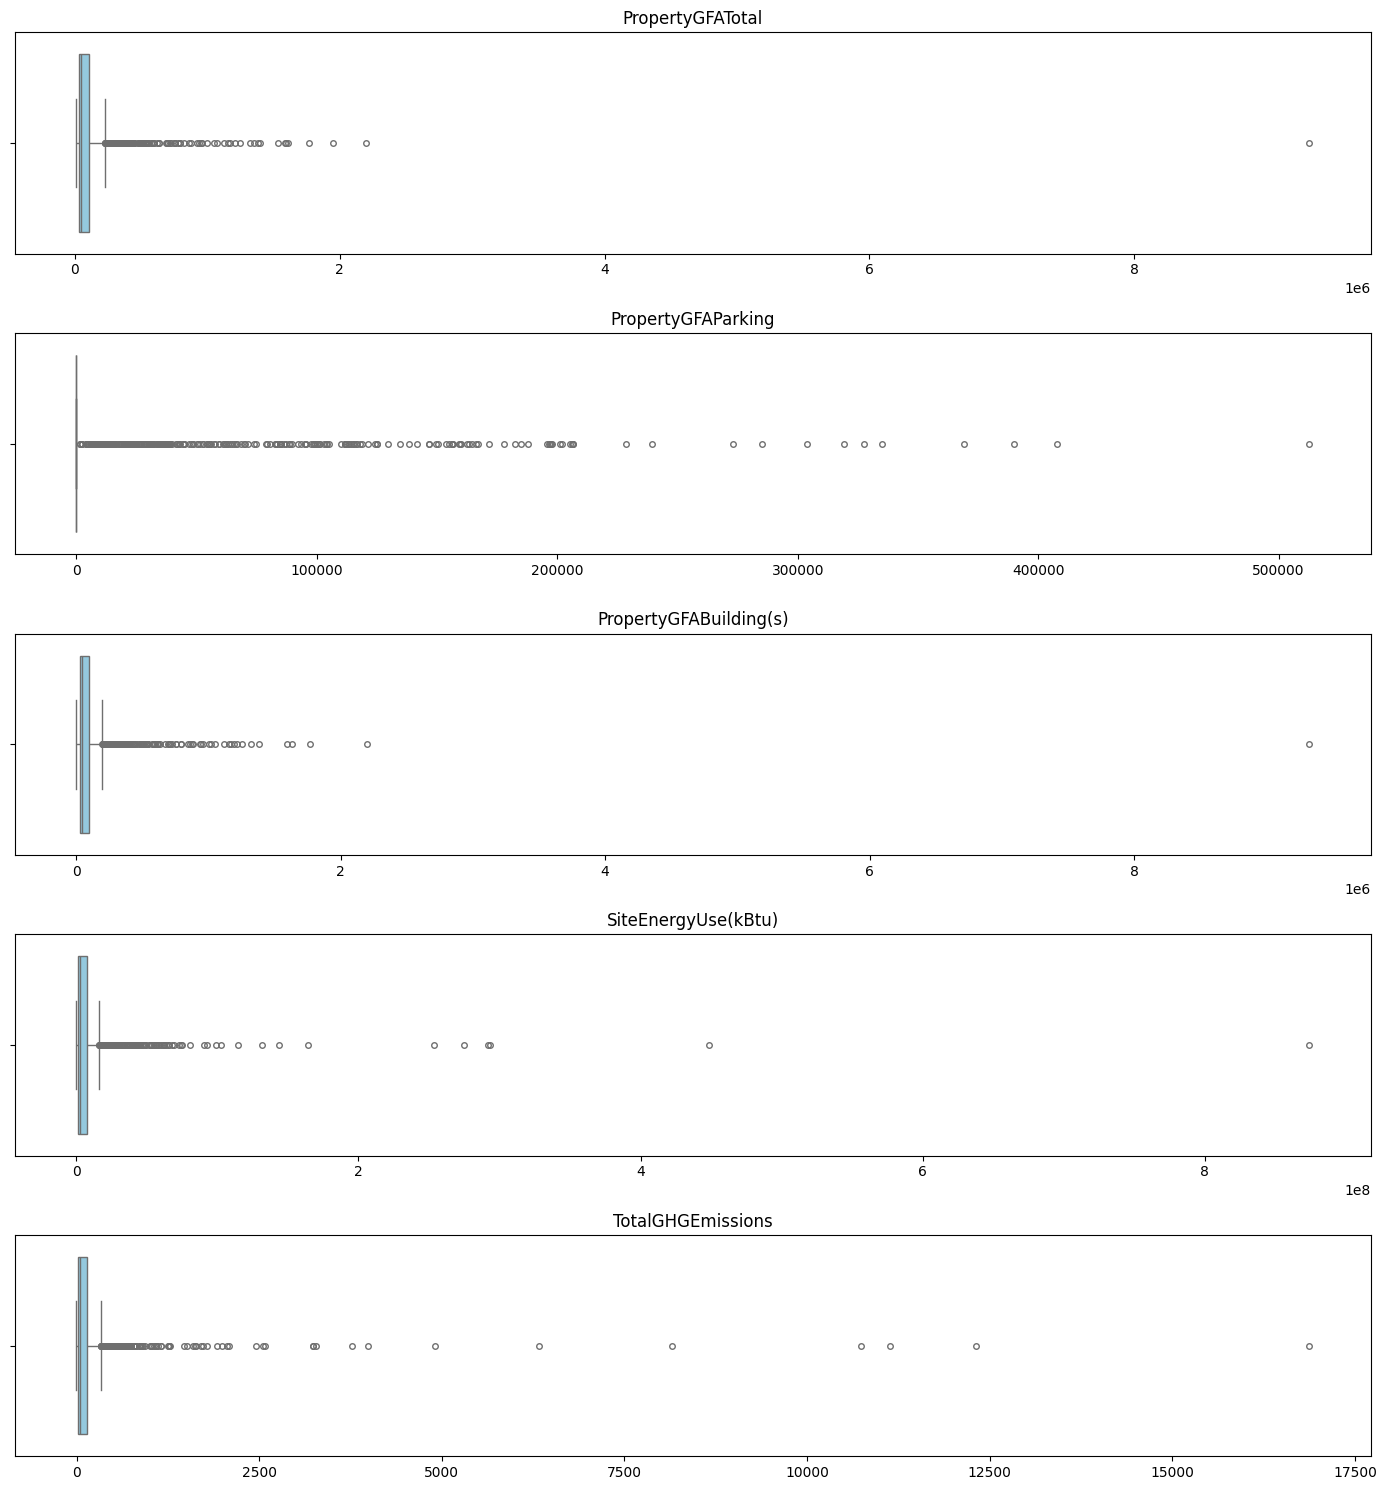

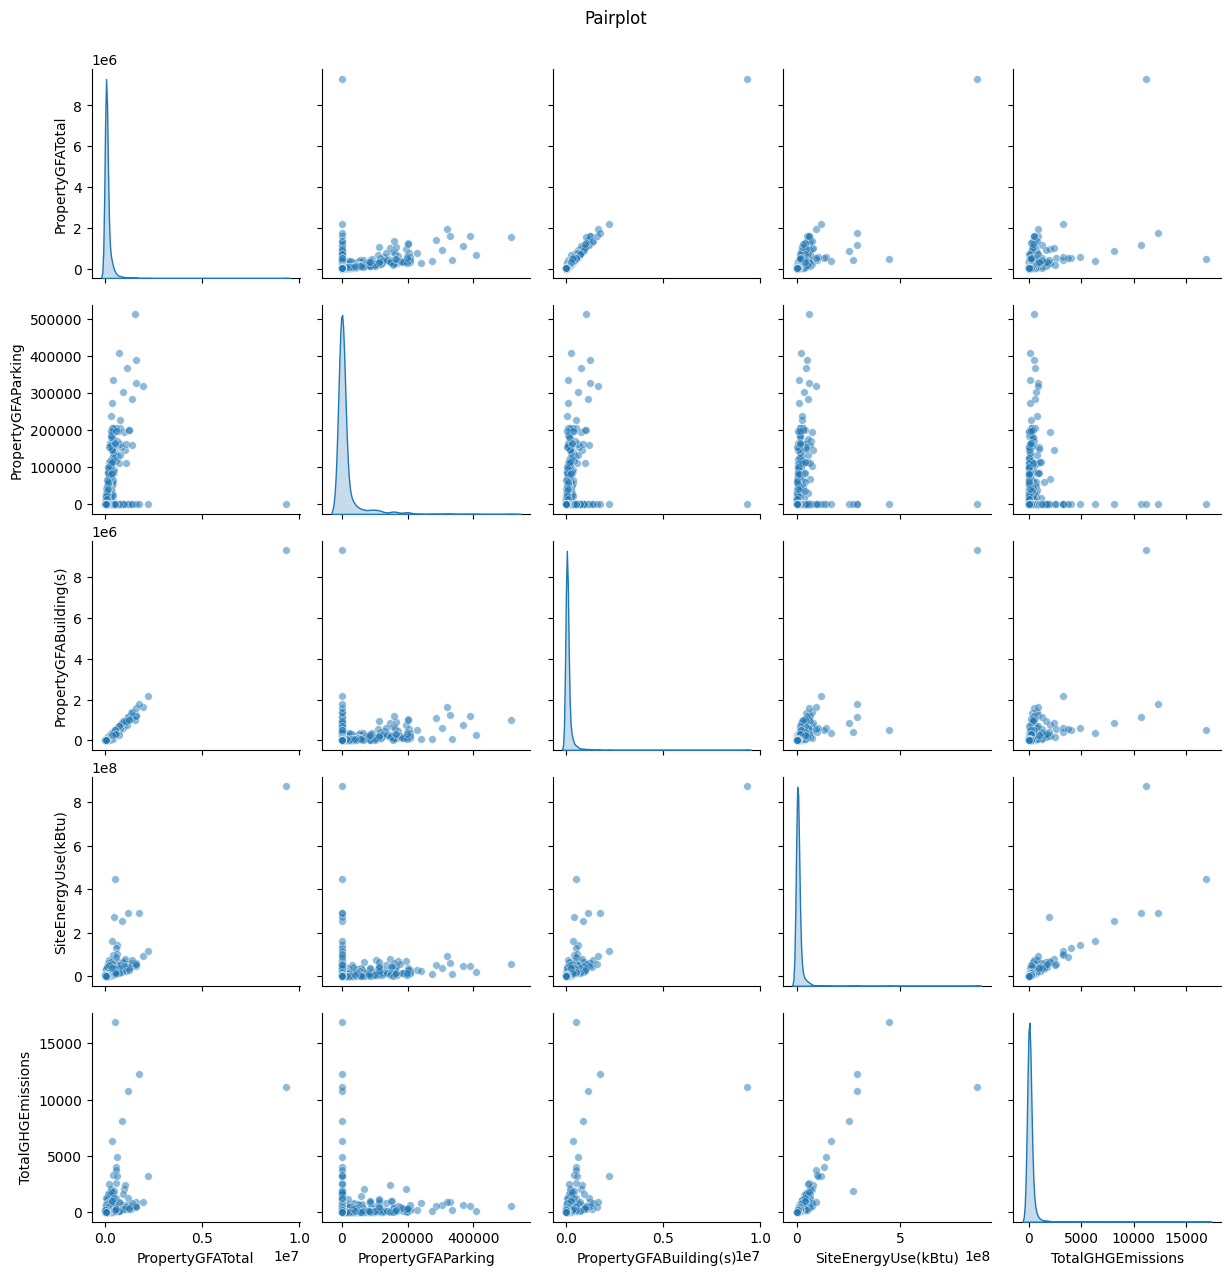

In [17]:
num_cols = [
    col for col in df.select_dtypes(include=['number']).columns
    if df[col].nunique() > 5
]

colonnes_interet = [
    "PropertyGFATotal", "PropertyGFAParking", "PropertyGFABuilding(s)",
    "SiteEnergyUse(kBtu)", "TotalGHGEmissions"
]
colonnes_interet = [c for c in colonnes_interet if c in num_cols]

plt.figure(figsize=(14, len(colonnes_interet)*3))
for i, col in enumerate(colonnes_interet, start=1):
    plt.subplot(len(colonnes_interet), 1, i)
    sns.boxplot(x=df[col], color="skyblue", fliersize=4)
    plt.title(f"{col}")
    plt.xlabel("")
plt.tight_layout()
plt.show()

if colonnes_interet:
    sns.pairplot(df[colonnes_interet], diag_kind="kde", plot_kws={'alpha': 0.5, 's': 30})
    plt.suptitle("Pairplot", y=1.02)
    plt.show()

In [18]:
seuils = {
    "PropertyGFATotal": 1_000_000,
    "PropertyGFAParking": 300_000,
    "PropertyGFABuilding(s)": 1_000_000,
    "SiteEnergyUse(kBtu)": 50_000_000,
    "TotalGHGEmissions": 5_000
}

for col, seuil in seuils.items():
    df = df[df[col] < seuil]


print(f"Nombre de lignes après nettoyage : {len(df)}")


Nombre de lignes après nettoyage : 1499


# Analyse de donnée de la target :

Statistiques de la target :
count    1.499000e+03
mean     5.647104e+06
std      7.759726e+06
min      5.713320e+04
25%      1.219804e+06
50%      2.582687e+06
75%      6.632090e+06
max      4.847999e+07
Name: SiteEnergyUse(kBtu), dtype: float64


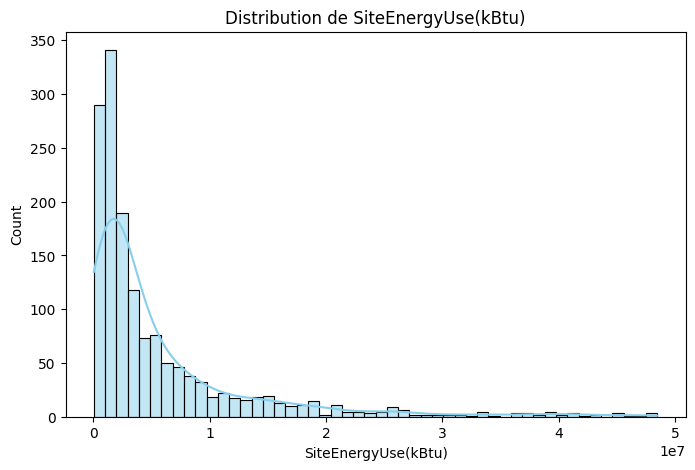

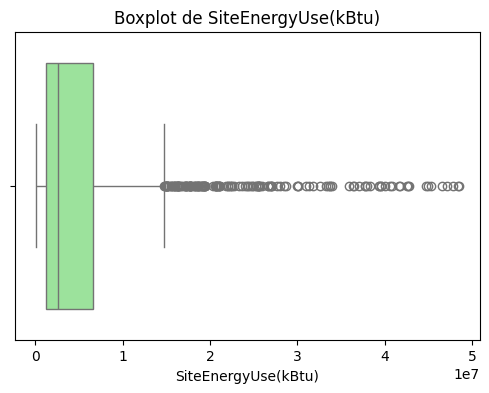

In [19]:


target = "SiteEnergyUse(kBtu)"

print("Statistiques de la target :")
print(df[target].describe())

plt.figure(figsize=(8,5))
sns.histplot(df[target], bins=50, kde=True, color="skyblue")
plt.title(f"Distribution de {target}")
plt.show()

# Boxplot
plt.figure(figsize=(6,4))
sns.boxplot(x=df[target], color="lightgreen")
plt.title(f"Boxplot de {target}")
plt.show()


## Analyse univariée

L’analyse univariée consiste à étudier **chaque variable indépendamment** afin de comprendre sa distribution, sa dispersion et la présence éventuelle de valeurs aberrantes.



In [20]:
# Liste des variables quantitatives (numériques)
quant_vars = df.select_dtypes(include=["number"]).columns.tolist()

# Liste des variables qualitatives (objet, bool, catégorie)
qual_vars = df.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

@interact(variable=widgets.Dropdown(options=quant_vars + qual_vars, description="Variable"))
def analyse_univariee(variable):
    plt.figure(figsize=(8,5))
    
    if variable in quant_vars:
        sns.histplot(df[variable].dropna(), bins=50, kde=True, color="skyblue")
        plt.title(f"Distribution de {variable}")
    else:
        df[variable].value_counts().head(15).plot(kind="bar", color="coral")
        plt.title(f"Top 15 catégories pour {variable}")
    
    plt.show()


interactive(children=(Dropdown(description='Variable', options=('OSEBuildingID', 'ZipCode', 'CouncilDistrictCo…

Corrélations quantitatives

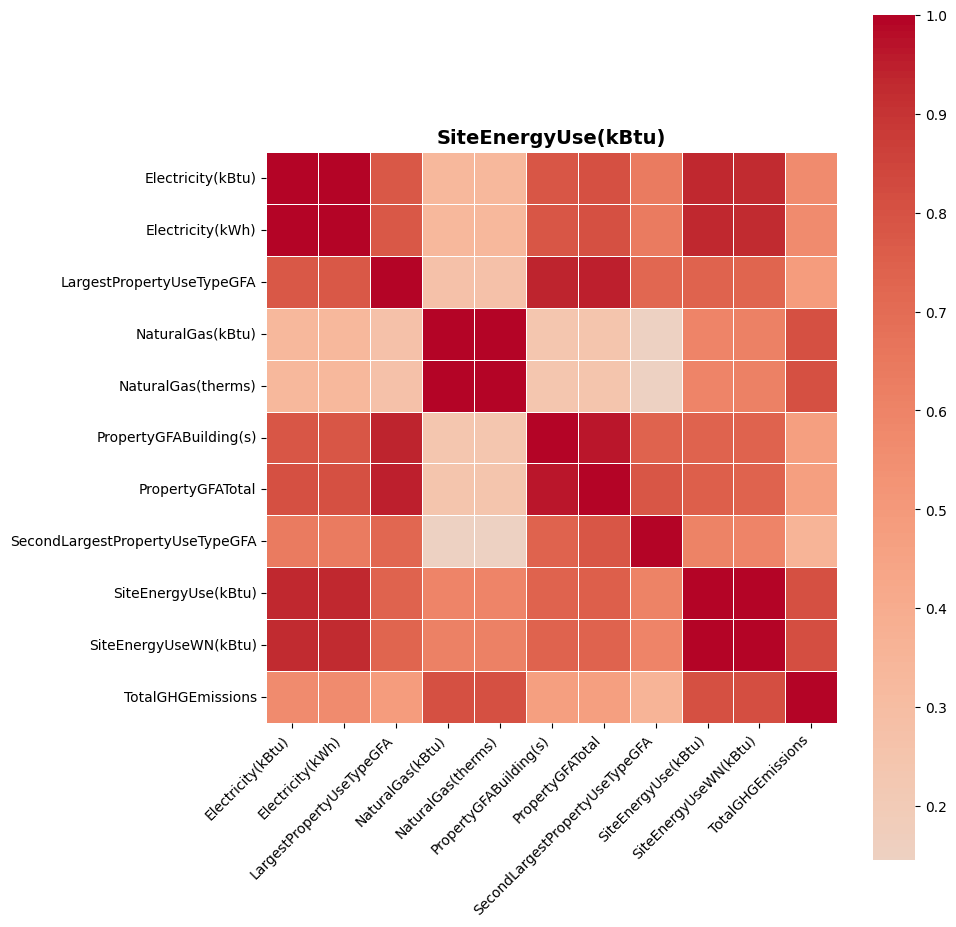

In [21]:
corr = df.corr(numeric_only=True)

target_corr = corr[target].drop(target).abs().sort_values(ascending=False)

top_features = target_corr.head(10).index

subset = corr.loc[top_features.union([target]), top_features.union([target])]

plt.figure(figsize=(10,10))
sns.heatmap(
    subset,
    annot=False, 
    cmap="coolwarm",
    center=0,
    cbar=True,
    square=True,
    linewidths=0.5,
    linecolor="white"
)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.title(f"{target}", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Analyse bivariée

L’analyse bivariée consiste à examiner **la relation entre deux variables**.

- **Quantitative × Quantitative** : scatterplots 
- **Quantitative × Qualitative** : boxplots 
- **Qualitative × Qualitative** : heatmaps



In [22]:
@interact(var_x=widgets.Dropdown(options=quant_vars + qual_vars, description="Variable X"),
          var_y=widgets.Dropdown(options=quant_vars + qual_vars, description="Variable Y"))
def analyse_bivariee(var_x, var_y):
    plt.figure(figsize=(8,5))
    # quanti × quanti
    if var_x in quant_vars and var_y in quant_vars:
        sns.scatterplot(x=df[var_x], y=df[var_y], alpha=0.5)
        plt.title(f"{var_x} vs {var_y}")
    # quanti × quali
    elif var_x in quant_vars and var_y in qual_vars:
        sns.boxplot(x=df[var_y], y=df[var_x])
        plt.title(f"{var_x} par {var_y}")
    
    elif var_x in qual_vars and var_y in quant_vars:
        sns.boxplot(x=df[var_x], y=df[var_y])
        plt.title(f"{var_y} par {var_x}")
    # quali × quali
    else:
        crosstab = pd.crosstab(df[var_x], df[var_y])
        sns.heatmap(crosstab, annot=True, fmt="d", cmap="Blues")
        plt.title(f"Contingence {var_x} / {var_y}")
    
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


interactive(children=(Dropdown(description='Variable X', options=('OSEBuildingID', 'ZipCode', 'CouncilDistrict…

In [23]:
df.to_csv("./assets/2016_Building_Energy_Benchmarking_clean.csv", index=False)